# Netflix Project Management
### *************************************************************************************************
## Netflix Global Expansion Strategy
## Challenge 2 — Data Analysis Project

### *************************************************************************************************

**Business question:** Which countries contribute the most content to Netflix, and where could Netflix expand next?

**Objective:** Analyze a Netflix-style catalogue by country, compare Movies and TV Shows, examine catalogue additions over time, and develop cautious recommendations.

### *************************************************************************************************



# Team Member Details and Roles

| No. | Team Member Name | Student Email | Division |
|---|---|---|---|
| 1 | Dhruv Joshi | 00102276@students.schiller.edu | Division B |


## 1. Import libraries
We use pandas and NumPy for data manipulation and Matplotlib/Seaborn for charts.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


### *******************************************************************************


## 2. Load the dataset
Keep `netflix_global_expansion_synthetic.csv` in the same folder as this notebook.

In [ ]:
DATA_PATH = Path("netflix_global_expansion_synthetic.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place netflix_global_expansion_synthetic.csv beside this notebook.")
netflix_raw = pd.read_csv(DATA_PATH)
netflix = netflix_raw.copy()
print("Shape:", netflix.shape)
### *************************************************************************************************
display(netflix.head())

Shape: (924, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s00348,TV Show,Lost Mystery 0348,R. Williams,"Liam Brown, Noah Smith",United Kingdom,"November 22, 2019",2007,PG-13,2 Seasons,Dramas,"A dramas title exploring themes of family, amb..."
1,s00225,TV Show,A Hearts 0225,S. Patel,"Noah Smith, Lucas Martin, Oliver Jones",NaN,"November 26, 2020",2016,TV-14,3 Seasons,Comedies,"A comedies title exploring themes of family, a..."
2,s00407,Movie,Lost Season 0407,K. Tanaka,"Emma Wilson, Yuna Kim",Brazil,"June 24, 2019",2016,R,120 min,Documentaries,A documentaries title exploring themes of fami...
3,s00586,Movie,A World 0586,S. Patel,Amira Hassan,"United States, Spain","April 26, 2021",2021,TV-14,87 min,International Movies,A international movies title exploring themes ...
4,s00248,TV Show,Final Stories 0248,S. Patel,"Priya Shah, Aarav Mehta","United States, Argentina","October 07, 2020",2002,TV-MA,2 Seasons,Crime TV Shows,A crime tv shows title exploring themes of fam...


### *************************************************************************************************

## 3. Initial inspection
Inspect the data types, summary statistics, missing values and duplicates before cleaning.

In [ ]:
print("Columns:", netflix.columns.tolist())
display(netflix.dtypes.to_frame("data_type"))
display(netflix.describe(include="all").T)
missing_before = netflix.isna().sum().to_frame("missing_count")
missing_before["missing_percent"] = (missing_before["missing_count"]/len(netflix)*100).round(2)
display(missing_before.sort_values("missing_count", ascending=False))
print("Exact duplicate rows:", netflix.duplicated().sum())

Columns: ['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']


,data_type
show_id,str
type,str
title,str
director,str
cast,str
country,str
date_added,str
release_year,int64
rating,str
duration,str


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,924,900,s00598,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,924,2,Movie,634,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,924,900,Final Season 0598,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,830,8,J. Smith,118,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,924,428,Isabella Rossi,33,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,869,166,United States,162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,896,610,"May 25, 2019",6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,924.0,NaN,NaN,NaN,2010.628788,6.295682,2000.0,2005.0,2011.0,2016.0,2021.0
rating,900,10,R,104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,897,87,3 Seasons,54,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent
director,94,10.17
country,55,5.95
date_added,28,3.03
duration,27,2.92
rating,24,2.60
title,0,0.00
show_id,0,0.00
type,0,0.00
release_year,0,0.00
cast,0,0.00


Exact duplicate rows: 23


### *************************************************************************************************


## 4. Data cleaning
### 4.1 Remove exact duplicate rows
Keep the original import in `netflix_raw` for reproducibility.

In [ ]:
before = len(netflix)
netflix = netflix.drop_duplicates().copy()
print("Rows before:", before)
print("Rows after:", len(netflix))
print("Duplicates removed:", before-len(netflix))

Rows before: 924
Rows after: 901
Duplicates removed: 23


### 4.2 Standardize text columns


In [ ]:
text_columns = ["type","title","director","cast","country","rating","duration","listed_in","description"]
for col in text_columns:
    netflix[col] = netflix[col].astype("string").str.strip()
    netflix[col] = netflix[col].replace({"":pd.NA,"nan":pd.NA,"None":pd.NA})
print("Text columns standardized.")

Text columns standardized.


### 4.3 Convert date and numeric columns
Invalid dates or years become missing rather than being guessed.

In [ ]:
netflix["date_added"] = pd.to_datetime(netflix["date_added"].astype("string").str.strip(), format="mixed", errors="coerce")
netflix["release_year"] = pd.to_numeric(netflix["release_year"], errors="coerce").astype("Int64")
display(netflix[["date_added","release_year"]].dtypes.to_frame("cleaned_type"))

,cleaned_type
date_added,datetime64[us]
release_year,Int64


### 4.4 Handle missing values


In [ ]:
netflix["country"] = netflix["country"].fillna("Unknown")
missing_after = netflix.isna().sum().to_frame("missing_count")
missing_after["missing_percent"] = (missing_after["missing_count"]/len(netflix)*100).round(2)
display(missing_after.sort_values("missing_count", ascending=True))

,missing_count,missing_percent
director,90,9.99
date_added,27,3.00
duration,26,2.89
rating,24,2.66
title,0,0.00
type,0,0.00
show_id,0,0.00
cast,0,0.00
release_year,0,0.00
country,0,0.00


### 4.5 Validate the cleaned data

In [ ]:
print("Cleaned shape:", netflix.shape)
print("Remaining duplicate rows:", netflix.duplicated().sum())
print("Unknown-country titles:", (netflix["country"]=="Unknown").sum())
print("Date range:", netflix["date_added"].min(), "to", netflix["date_added"].max())
### *************************************************************************************************
display(netflix.head())

Cleaned shape: (901, 12)
Remaining duplicate rows: 1
Unknown-country titles: 49
Date range: 2019-01-01 00:00:00 to 2021-12-29 00:00:00


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s00348,TV Show,Lost Mystery 0348,R. Williams,"Liam Brown, Noah Smith",United Kingdom,2019-11-22,2007,PG-13,2 Seasons,Dramas,"A dramas title exploring themes of family, amb..."
1,s00225,TV Show,A Hearts 0225,S. Patel,"Noah Smith, Lucas Martin, Oliver Jones",Unknown,2020-11-26,2016,TV-14,3 Seasons,Comedies,"A comedies title exploring themes of family, a..."
2,s00407,Movie,Lost Season 0407,K. Tanaka,"Emma Wilson, Yuna Kim",Brazil,2019-06-24,2016,R,120 min,Documentaries,A documentaries title exploring themes of fami...
3,s00586,Movie,A World 0586,S. Patel,Amira Hassan,"United States, Spain",2021-04-26,2021,TV-14,87 min,International Movies,A international movies title exploring themes ...
4,s00248,TV Show,Final Stories 0248,S. Patel,"Priya Shah, Aarav Mehta","United States, Argentina",2020-10-07,2002,TV-MA,2 Seasons,Crime TV Shows,A crime tv shows title exploring themes of fam...


### ******************************************************************************

## 5. Prepare country-level analysis data


In [ ]:
country_records = netflix[["show_id","title","type","country","release_year","date_added"]].copy()
country_records["country"] = country_records["country"].str.split(",")
country_records = country_records.explode("country")
country_records["country"] = country_records["country"].astype("string").str.strip()
country_records = country_records[country_records["country"].notna() & (country_records["country"]!="")]
country_records = country_records.drop_duplicates(subset=["show_id","country"])
known_country_records = country_records[country_records["country"]!="Unknown"].copy()
print("Unique titles:", netflix["show_id"].nunique())
print("Title-country records:", len(country_records))
print("Known countries:", known_country_records["country"].nunique())
display(known_country_records.head())

Unique titles: 900
Title-country records: 1086
Known countries: 24


,show_id,title,type,country,release_year,date_added
0,s00348,Lost Mystery 0348,TV Show,United Kingdom,2007,2019-11-22
2,s00407,Lost Season 0407,Movie,Brazil,2016,2019-06-24
3,s00586,A World 0586,Movie,United States,2021,2021-04-26
3,s00586,A World 0586,Movie,Spain,2021,2021-04-26
4,s00248,Final Stories 0248,TV Show,United States,2002,2020-10-07


### ******************************************************************************
## 6. Exploratory Data Analysis (EDA)
### 6.1 Overall catalogue composition

,title_count
type,
Movie,615
TV Show,286


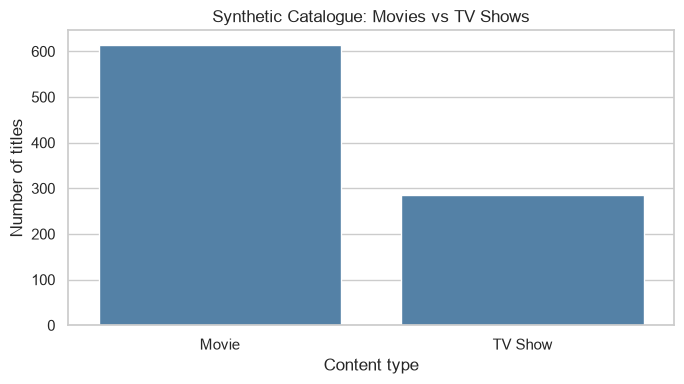

In [ ]:
type_counts = netflix["type"].value_counts()
display(type_counts.to_frame("title_count"))
plt.figure(figsize=(7,4))
sns.barplot(x=type_counts.index, y=type_counts.values, color="steelblue")
plt.title("Synthetic Catalogue: Movies vs TV Shows")
plt.xlabel("Content type"); plt.ylabel("Number of titles")
plt.tight_layout(); plt.show()

**Interpretation:** State which content type has the larger count using the output. These are generated sample records, not official Netflix figures.



### 6.2 Top 10 countries by title contribution

,title_count
country,
United States,222
India,111
United Kingdom,92
South Korea,65
Japan,61
Canada,51
Germany,51
Spain,44
Turkey,39


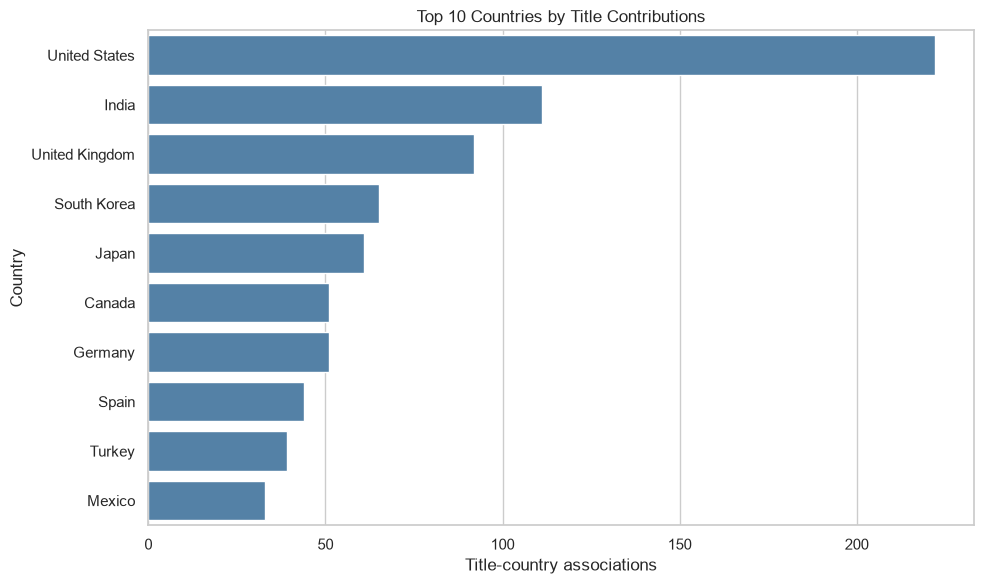

In [ ]:
country_counts = known_country_records.groupby("country")["show_id"].nunique().sort_values(ascending=False)
top_10 = country_counts.head(10)
display(top_10.to_frame("title_count"))
plt.figure(figsize=(10,6))
sns.barplot(x=top_10.values, y=top_10.index, color="steelblue")
plt.title("Top 10 Countries by Title Contributions")
plt.xlabel("Title-country associations"); plt.ylabel("Country")
plt.tight_layout(); plt.show()

**Interpretation:** Identify the top three countries. Remember that multi-country titles contribute to more than one country's count.

### 6.3 Movies vs TV Shows by country

type,Movie,TV Show
country,,
Canada,35,16
Germany,27,24
India,71,40
Japan,40,21
Mexico,23,10
South Korea,43,22
Spain,36,8
Turkey,29,10
United Kingdom,64,28


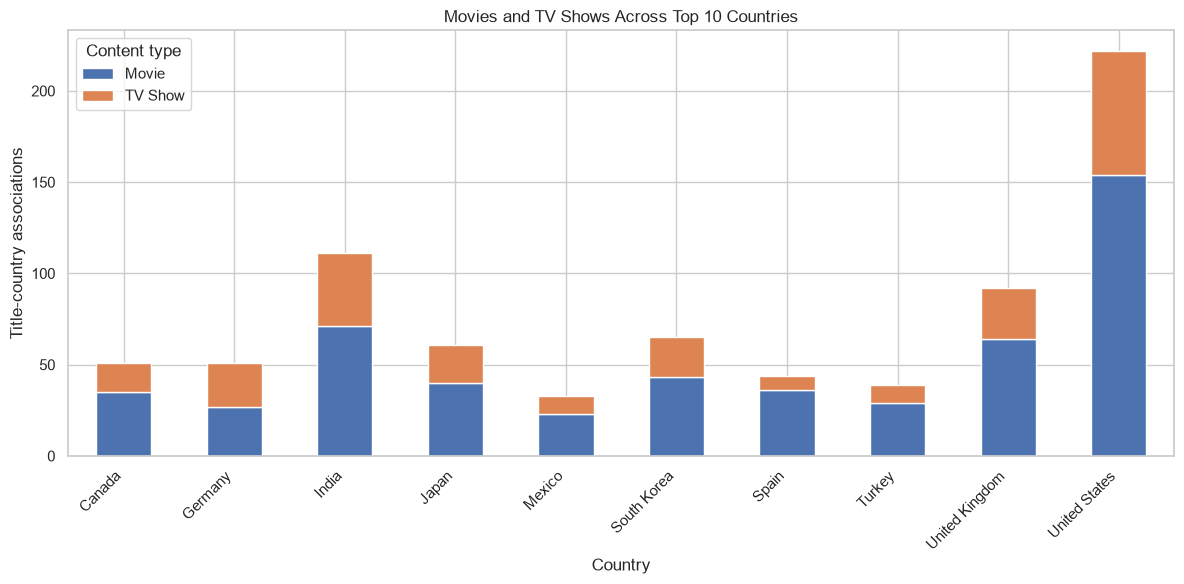

In [ ]:
top_names = top_10.index
country_type = (known_country_records[known_country_records["country"].isin(top_names)]
                .groupby(["country","type"])["show_id"].nunique().unstack(fill_value=0))
display(country_type)
country_type.plot(kind="bar", stacked=True, figsize=(12,6))
plt.title("Movies and TV Shows Across Top 10 Countries")
plt.xlabel("Country"); plt.ylabel("Title-country associations")
plt.xticks(rotation=45, ha="right"); plt.legend(title="Content type")
plt.tight_layout(); plt.show()

### 6.4 Catalogue additions over time


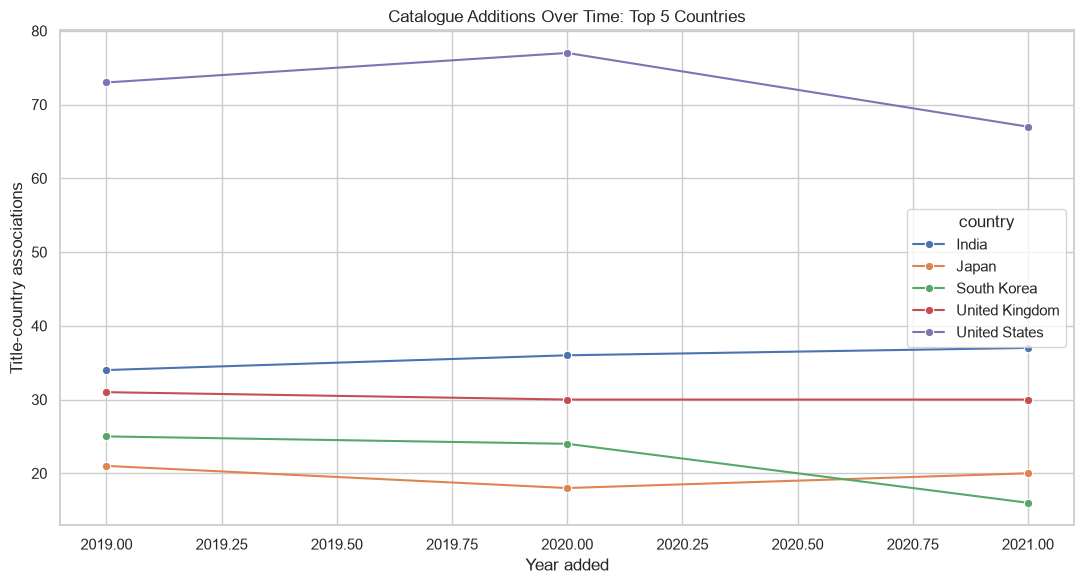

,year_added,country,title_count
0,2019,India,34
1,2019,Japan,21
2,2019,South Korea,25
3,2019,United Kingdom,31
4,2019,United States,73
5,2020,India,36
6,2020,Japan,18
7,2020,South Korea,24
8,2020,United Kingdom,30
9,2020,United States,77


In [ ]:
dated = known_country_records.dropna(subset=["date_added"]).copy()
dated["year_added"] = dated["date_added"].dt.year
top_5 = country_counts.head(5).index
country_year = (dated[dated["country"].isin(top_5)]
                .groupby(["year_added","country"])["show_id"].nunique().reset_index(name="title_count"))
plt.figure(figsize=(11,6))
sns.lineplot(data=country_year, x="year_added", y="title_count", hue="country", marker="o")
plt.title("Catalogue Additions Over Time: Top 5 Countries")
plt.xlabel("Year added"); plt.ylabel("Title-country associations")
plt.tight_layout(); plt.show()
display(country_year.head(15))

### 6.5 Release-year distribution


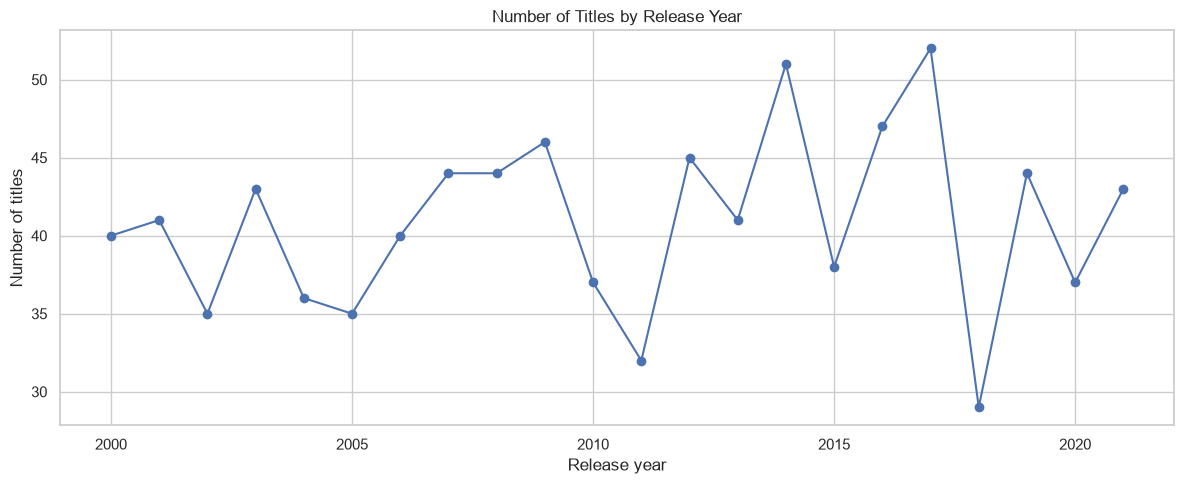

In [ ]:
release_counts = netflix.dropna(subset=["release_year"]).groupby("release_year")["show_id"].nunique()
plt.figure(figsize=(12,5))
release_counts.plot(kind="line", marker="o")
plt.title("Number of Titles by Release Year")
plt.xlabel("Release year"); plt.ylabel("Number of titles")
plt.tight_layout(); plt.show()

### ******************************************************************************
## 7. Country screening for further research


In [ ]:
country_summary = country_counts.rename("title_count").reset_index().sort_values(["title_count","country"])
print("Lowest recorded contributions in this sample:")
display(country_summary.head(10))
print("Highest recorded contributions in this sample:")
display(country_summary.sort_values("title_count", ascending=False).head(10))

Lowest recorded contributions in this sample:


,country,title_count
23,Denmark,13
21,Poland,15
22,South Africa,15
20,Sweden,15
19,Indonesia,16
18,Philippines,17
17,Argentina,19
16,Thailand,19
14,Australia,20
15,Egypt,20


Highest recorded contributions in this sample:


,country,title_count
0,United States,222
1,India,111
2,United Kingdom,92
3,South Korea,65
4,Japan,61
5,Canada,51
6,Germany,51
7,Spain,44
8,Turkey,39
9,Mexico,33


### ******************************************************************************

## 8. Business Insights

1. **Top Content-Producing Countries:**  
   The United States contributes the highest number of titles (222), followed by India (111) and the United Kingdom (92). These countries are important contributors to Netflix's content library.

2. **Movies vs. TV Shows:**  
   Movies (615 titles) are more common than TV Shows (286 titles). This shows that movies make up the larger part of the analysed content.

3. **Strong Asian Content Markets:**  
   India, South Korea, and Japan contribute a significant number of titles. This highlights the importance of Asian content in Netflix's international catalogue.

4. **Content Growth Over Time:**  
   The United States added 73 titles in 2019, 77 in 2020, and 67 in 2021. India also showed consistent additions, with 34, 36, and 37 titles respectively.

5. **Countries with Lower Content Representation:**  
   Denmark, Poland, South Africa, and Sweden have comparatively fewer titles. These countries could be considered for further market research.

### ******************************************************************************
## 10. Business Recommendations

1. **Continue Investing in Strong Markets:**  
   Netflix should continue developing content in the United States, India, and the United Kingdom because they contribute a large number of titles.

2. **Develop More Regional Content:**  
   Netflix should explore more local-language movies and TV shows in India, South Korea, and Japan to serve different audience preferences.

3. **Research New Markets:**  
   Netflix should investigate countries with lower content representation, such as Denmark, Poland, and South Africa, to identify possible expansion opportunities.

4. **Maintain a Balanced Content Library:**  
   Since movies are more common than TV shows, Netflix could explore adding more TV series to provide a wider range of content.

5. **Use Customer Data for Decisions:**  
   Before expanding into a new country, Netflix should study customer demand, viewing hours, subscriptions, and audience preferences.

### ******************************************************************************

## 10. Final conclusion

The analysis shows that the United States, India, and the United Kingdom are the leading countries contributing content to Netflix's library.

Movies represent the largest content category, while TV Shows also contribute an important part of the catalogue. Asian countries such as India, South Korea, and Japan show strong content contributions.

The analysis also identifies countries with lower content representation that could be explored for future opportunities.

Based on these findings, Netflix should continue investing in its strong markets, develop more regional content, and research new markets before making expansion decisions.

Overall, this project demonstrates how data analysis can help businesses understand content distribution, identify opportunities, and make better strategic decisions.

